In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
from scipy import ndimage
import scipy.signal as signal
import pickle
import math
import pygame
import cv2

from notebooks.imports import *
from src.utils import pmf_utils

from scripts.ucla_rdk import DotMotionStim as RDK_ucla
from scripts.uw_rdk import RandomDotMotion as RDK_uw
from scripts import motion_energy

pygame 2.6.1 (SDL 2.28.4, Python 3.10.12)
Hello from the pygame community. https://www.pygame.org/contribute.html


### Config

In [3]:
from config import dir_config

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)

### Load and Preprocess data

In [4]:
data = pd.read_csv(Path(processed_dir, "valid_data.csv"), index_col=None)


# convert pulse info to frame units
convert_to_frame = 1000 / 16.67
data["pulse_onset_frame"] = np.round(data.pulse_onset * convert_to_frame) + 1
data["pulse_offset_frame"] = np.round(data.pulse_onset_frame + (data.pulse_duration * convert_to_frame))
data["rt_frame"] = np.ceil(data.reaction_time * convert_to_frame) + 1

data

,idx_session,data_source,subject_id,session_id,idx_valid_trial,idx_correction,is_correction_trial,signed_coherence,target,choice,reaction_time,outcome,reward_amount,fixation_duration,stimulus_duration,reinforcement_duration,intertrial_delay,is_pulse_trial,pulse_onset,pulse_duration,pulse_coherence,stimulus_seed,pulse_type,pulse_onset_frame,pulse_offset_frame,rt_frame
0,0,uw,DBM11,10_1,1,0,False,100,1,1,1.080817,1.0,1.5,0.530901,25.0,0.0,0.500000,True,0.416750,0.066680,-100,612658,-3.0,26.0,30.0,66.0
1,0,uw,DBM11,10_1,2,0,False,100,1,0,0.469520,0.0,NaN,0.577326,25.0,0.0,13.689771,False,0.416750,0.066680,100,463182,0.0,26.0,30.0,30.0
2,0,uw,DBM11,10_1,3,0,False,-100,-1,0,2.171707,1.0,1.5,0.556890,25.0,0.0,0.500000,True,0.416750,0.066680,100,165712,3.0,26.0,30.0,132.0
3,0,uw,DBM11,10_1,4,0,False,-100,-1,0,0.476003,1.0,1.5,0.548262,25.0,0.0,0.500000,False,0.050010,0.066680,-100,418800,-0.0,4.0,8.0,30.0
4,0,uw,DBM11,10_1,5,0,False,-100,-1,0,0.971870,1.0,1.5,0.561377,25.0,0.0,0.500000,False,0.233380,0.066680,-100,372882,-0.0,15.0,19.0,60.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113869,297,ucla,PSUIM9,9_1,346,0,False,18,1,1,1.108688,1.0,2.6,1.000000,60.0,0.5,0.250000,True,0.029568,0.050560,100,346,1.0,3.0,6.0,68.0
113870,297,ucla,PSUIM9,9_1,347,0,False,36,1,1,1.598707,1.0,2.6,1.000000,60.0,0.5,0.250000,False,NaN,NaN,0,347,0.0,NaN,NaN,97.0
113871,297,ucla,PSUIM9,9_1,348,0,False,-9,-1,1,2.292042,0.0,0.0,1.000000,60.0,1.5,0.252608,False,NaN,NaN,0,348,0.0,NaN,NaN,139.0
113872,297,ucla,PSUIM9,9_1,349,0,False,36,1,1,1.706793,1.0,2.6,1.000000,60.0,0.5,0.250000,True,0.240538,0.050291,100,349,2.0,15.0,18.0,104.0


### Utils

### Helper Functions

In [5]:
rdk_ucla = RDK_ucla()
rdk_uw = RDK_uw()

#### Generate Stimulus with Matplotlib

In [18]:
def draw_stimulus_cv(rdk):
	"""Draws stimulus using numpy array and OpenCV."""
	img = np.zeros((rdk_uw.stimulus_size[1], rdk_uw.stimulus_size[0]), dtype=np.uint8)
	for x, y in zip(rdk.x, rdk.y):
		center = (int(x), int(y))
		cv2.circle(img, center, rdk.radius, int(rdk.color[0]), -1)  # grayscale color
	return img


def get_stimulus_array_uw(screen_resolution, rdk, pars, rt_frame, down_sample_fact=5):
	resolution = (int(screen_resolution[1] / down_sample_fact), int(screen_resolution[0] / down_sample_fact))
	stimulus_array = np.zeros((rt_frame, resolution[1], resolution[0]))

	pulses = pars.get("pulse", ([], []))

	for i in range(rt_frame):
		if i == 0:
			rdk.new_stimulus(pars)  # Initialize the stimulus
		elif pulses and i == pulses[0][0] - 1:
			rdk.move_dots(new_coherence=pulses[0][1])
			pulses.pop(0)
		else:
			rdk.move_dots()

		stimulus_array[i, :, :] = cv2.resize(draw_stimulus_cv(rdk), resolution)
	stimulus_array /= np.max(stimulus_array)

	return stimulus_array.astype(np.uint8)


def get_stimulus_array_ucla(screen_resolution, rdk, pars, rt_frame, down_sample_fact=5):
	resolution = (int(screen_resolution[1] / down_sample_fact), int(screen_resolution[0] / down_sample_fact))
	stimulus_array = np.zeros((rt_frame, resolution[1], resolution[0]))

	pulses = pars.get("pulse", ([], []))

	for i in range(rt_frame):
		if i == 0:
			rdk.newStimulus(pars['coherence'], pars['seed'])  # Initialize the stimulus
		elif pulses and i == pulses[0][0] - 1:
			rdk.updateBurst(burstCoherence=pulses[0][1])
			pulses.pop(0)
		else:
			rdk.moveDots()

		stimulus_array[i, :, :] = cv2.resize(draw_stimulus_cv(rdk), resolution)
	stimulus_array /= np.max(stimulus_array)

	return stimulus_array.astype(np.uint8)

In [7]:
stimulus_info = data[['stimulus_seed', 'signed_coherence', 'pulse_coherence', 'pulse_onset_frame', 'pulse_offset_frame', 'rt_frame', 'data_source']]

stimulus_info

,stimulus_seed,signed_coherence,pulse_coherence,pulse_onset_frame,pulse_offset_frame,rt_frame,data_source
0,612658,100,-100,26.0,30.0,66.0,uw
1,463182,100,100,26.0,30.0,30.0,uw
2,165712,-100,100,26.0,30.0,132.0,uw
3,418800,-100,-100,4.0,8.0,30.0,uw
4,372882,-100,-100,15.0,19.0,60.0,uw
...,...,...,...,...,...,...,...
113869,346,18,100,3.0,6.0,68.0,ucla
113870,347,36,0,NaN,NaN,97.0,ucla
113871,348,-9,0,NaN,NaN,139.0,ucla
113872,349,36,100,15.0,18.0,104.0,ucla


---
---

In [ ]:
import numpy as np
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

# --- CONFIGURATION ---
output_dir = Path(processed_dir) / "stimuli_temp"
output_dir.mkdir(parents=True, exist_ok=True)

batch_size = 100
max_workers = 16
down_sample_fact = 5
screen_resolution = (1280, 720)


# --- UTILITIES ---
def batched(iterable, batch_size):
	for i in range(0, len(iterable), batch_size):
		yield iterable[i : i + batch_size]


def safe_int(val, default=0):
	try:
		return int(val)
	except (ValueError, TypeError):
		return default


# --- WORKER FUNCTION ---
def process_and_save_row_npz(row_dict, index, rdk_ucla, rdk_uw):
	try:
		output_path = output_dir / f"stimulus_{index}.npz"
		if output_path.exists():
			print(f"[{index}] Exists. Skipping.")
			return

		pars = {
			"seed": row_dict["stimulus_seed"],
			"coherence": 100,
		}

		if row_dict["pulse_onset_frame"] is not None and row_dict["pulse_offset_frame"] is not None:
			pars["pulse"] = [
				(safe_int(row_dict["pulse_onset_frame"]), row_dict["pulse_coherence"]),
				(safe_int(row_dict["pulse_offset_frame"]), row_dict["signed_coherence"]),
			]

		rt_frame = safe_int(row_dict["rt_frame"])

		# Select the appropriate RDK object based on data source
		if row_dict["data_source"] == "ucla":
			array = get_stimulus_array_ucla(screen_resolution, rdk_ucla, pars, rt_frame, down_sample_fact)
		else:
			array = get_stimulus_array_uw(screen_resolution, rdk_uw, pars, rt_frame, down_sample_fact)

		np.savez_compressed(output_path, stimulus=array)

	except Exception as e:
		print(f"[{index}] Error: {e}")


# --- MAIN EXECUTION ---
rdk_ucla = RDK_ucla()
rdk_uw = RDK_uw()

rows = [
	{
		"stimulus_seed": row.stimulus_seed,
		"pulse_onset_frame": row.pulse_onset_frame,
		"pulse_coherence": row.pulse_coherence,
		"pulse_offset_frame": row.pulse_offset_frame,
		"signed_coherence": row.signed_coherence,
		"rt_frame": row.rt_frame,
		"data_source": row.data_source,
	}
	for row in stimulus_info.itertuples(index=False)
]

total_batches = len(rows) // batch_size + int(len(rows) % batch_size != 0)

for batch_index, batch in enumerate(batched(rows, batch_size)):
	start_idx = batch_index * batch_size
	print(f"\n🔁 Batch {batch_index + 1}/{total_batches}...")

	with ProcessPoolExecutor(max_workers=max_workers) as executor:
		futures = [executor.submit(process_and_save_row_npz, row_dict, start_idx + i, rdk_ucla, rdk_uw) for i, row_dict in enumerate(batch)]

		for future in as_completed(futures):
			try:
				future.result()
			except Exception as e:
				print(f"Process error: {e}")



🔁 Batch 1/1139...

🔁 Batch 2/1139...

🔁 Batch 3/1139...

🔁 Batch 4/1139...

🔁 Batch 5/1139...

🔁 Batch 6/1139...

🔁 Batch 7/1139...

🔁 Batch 8/1139...

🔁 Batch 9/1139...

🔁 Batch 10/1139...

🔁 Batch 11/1139...

🔁 Batch 12/1139...

🔁 Batch 13/1139...

🔁 Batch 14/1139...

🔁 Batch 15/1139...

🔁 Batch 16/1139...

🔁 Batch 17/1139...

🔁 Batch 18/1139...

🔁 Batch 19/1139...

🔁 Batch 20/1139...

🔁 Batch 21/1139...

🔁 Batch 22/1139...

🔁 Batch 23/1139...

🔁 Batch 24/1139...

🔁 Batch 25/1139...

🔁 Batch 26/1139...

🔁 Batch 27/1139...

🔁 Batch 28/1139...

🔁 Batch 29/1139...

🔁 Batch 30/1139...

🔁 Batch 31/1139...

🔁 Batch 32/1139...

🔁 Batch 33/1139...

🔁 Batch 34/1139...

🔁 Batch 35/1139...

🔁 Batch 36/1139...

🔁 Batch 37/1139...

🔁 Batch 38/1139...

🔁 Batch 39/1139...

🔁 Batch 40/1139...

🔁 Batch 41/1139...

🔁 Batch 42/1139...

🔁 Batch 43/1139...

🔁 Batch 44/1139...

🔁 Batch 45/1139...

🔁 Batch 46/1139...

🔁 Batch 47/1139...

🔁 Batch 48/1139...

🔁 Batch 49/1139...

🔁 Batch 50/1139...

🔁 Batch 

---
---

## Filters

In [6]:
## RDK with pulse
import pickle
import math
import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage
from src.utils.StimtoArray import get_RDK
import torch
import torch.nn.functional as F
import numpy as np


In [7]:
def f1(x, y, sigma_c=0.35, sigma_g=0.05):
	alpha = np.arctan(x / sigma_c)
	return (np.cos(alpha) ** 4) * (np.cos(4 * alpha)) * np.exp((-(y**2)) / (2 * sigma_g**2))


def f2(x, y, sigma_c=0.35, sigma_g=0.05):
	alpha = np.arctan(x / sigma_c)
	return (np.cos(alpha) ** 4) * (np.sin(4 * alpha)) * np.exp((-(y**2)) / (2 * sigma_g**2))


def g1(t):
	return ((60 * t) ** 3) * (np.exp(-60 * t)) * ((1 / math.factorial(3)) - (((60 * t) ** 2) / math.factorial(3 + 2)))


def g2(t):
	return ((60 * t) ** 5) * (np.exp(-60 * t)) * ((1 / math.factorial(5)) - (((60 * t) ** 2) / math.factorial(5 + 2)))


def create_filters(x_space=None, y_space=None, t_space=None, pixels_per_degree=10):
	x_space = np.arange(-0.7, 0.7, 0.05) if x_space is None else x_space
	y_space = np.arange(-0.7, 0.7, 0.05) if y_space is None else y_space
	t_space = np.arange(0, 0.2, 0.01) if t_space is None else t_space

	# Linear Spatiotemporal Filter (XT) at specific Y value
	Filter_XT_left1 = np.empty((len(t_space), len(x_space), len(y_space)))
	Filter_XT_left2 = np.empty((len(t_space), len(x_space), len(x_space)))
	Filter_XT_right1 = np.empty((len(t_space), len(x_space), len(x_space)))
	Filter_XT_right2 = np.empty((len(t_space), len(x_space), len(x_space)))
	for i, t in enumerate(t_space):
		for j, x in enumerate(x_space):
			Filter_XT_right1[i, j, :] = f1(x, y_space) * g1(t) + f2(x, y_space) * g2(t)
			Filter_XT_right2[i, j, :] = f2(x, y_space) * g1(t) - f1(x, y_space) * g2(t)
			Filter_XT_left1[i, j, :] = f1(x, y_space) * g1(t) - f2(x, y_space) * g2(t)
			Filter_XT_left2[i, j, :] = f2(x, y_space) * g1(t) + f1(x, y_space) * g2(t)
	right_filters = [Filter_XT_right1, Filter_XT_right2]
	left_filters = [Filter_XT_left1, Filter_XT_left2]

	return right_filters, left_filters


# def Calculate_ME_GPU(stimulus_array, right_filters, left_filters, padding="same", device="cuda"):
# 	# Convert stimulus array to PyTorch tensor and move to GPU
# 	if stimulus_array.ndim == 3:
# 		stimulus_tensor = torch.tensor(stimulus_array).unsqueeze(0).unsqueeze(0).float().to(device)  # (B, C, T, H, W)
# 	elif stimulus_array.ndim == 4:
# 		stimulus_tensor = torch.tensor(stimulus_array).unsqueeze(1).float().to(device)
# 	else:
# 		raise ValueError("Invalid stimulus array shape")

# 	# Convert filters to PyTorch tensors and move to GPU
# 	right_filters_tensor = [torch.tensor(f).float().unsqueeze(0).unsqueeze(0).to(device) for f in right_filters]
# 	left_filters_tensor = [torch.tensor(f).float().unsqueeze(0).unsqueeze(0).to(device) for f in left_filters]

# 	# Convolution: Original direction
# 	ME_r1_fwd = F.conv3d(stimulus_tensor, right_filters_tensor[0], padding=padding)
# 	ME_r2_fwd = F.conv3d(stimulus_tensor, right_filters_tensor[1], padding=padding)
# 	ME_l1_fwd = F.conv3d(stimulus_tensor, left_filters_tensor[0], padding=padding)
# 	ME_l2_fwd = F.conv3d(stimulus_tensor, left_filters_tensor[1], padding=padding)

# 	ME_fwd = (ME_r1_fwd**2 + ME_r2_fwd**2) - (ME_l1_fwd**2 + ME_l2_fwd**2)

# 	# Flip stimulus along time (dim=2), convolve again
# 	stimulus_tensor_reversed = torch.flip(stimulus_tensor, dims=[2])

# 	ME_r1_rev = F.conv3d(stimulus_tensor_reversed, right_filters_tensor[0], padding=padding)
# 	ME_r2_rev = F.conv3d(stimulus_tensor_reversed, right_filters_tensor[1], padding=padding)
# 	ME_l1_rev = F.conv3d(stimulus_tensor_reversed, left_filters_tensor[0], padding=padding)
# 	ME_l2_rev = F.conv3d(stimulus_tensor_reversed, left_filters_tensor[1], padding=padding)

# 	ME_rev = (ME_r1_rev**2 + ME_r2_rev**2) - (ME_l1_rev**2 + ME_l2_rev**2)

# 	# Flip reversed result back along time
# 	ME_rev_flipped = torch.flip(ME_rev, dims=[2])

# 	# Average the forward and backward convolved motion energy
# 	ME = 0.5 * (ME_fwd + ME_rev_flipped)
# 	return ME.squeeze(1).cpu().numpy()


In [8]:
def Calculate_ME_GPU(stimulus_array, right_filters_tensor, left_filters_tensor, padding="same", device="cuda"):
	# Convert stimulus array to PyTorch tensor and move to GPU
	stimulus_tensor = torch.tensor(stimulus_array).unsqueeze(0).unsqueeze(0).float().to(device)  # (B, C, T, H, W)

	# Forward
	ME_fwd = (
		F.conv3d(stimulus_tensor, right_filters_tensor[0], padding="same") ** 2
		+ F.conv3d(stimulus_tensor, right_filters_tensor[1], padding="same") ** 2
		- F.conv3d(stimulus_tensor, left_filters_tensor[0], padding="same") ** 2
		- F.conv3d(stimulus_tensor, left_filters_tensor[1], padding="same") ** 2
	)

	# Reverse
	stim_reversed = torch.flip(stimulus_tensor, dims=[2])
	ME_rev = (
		F.conv3d(stim_reversed, right_filters_tensor[0], padding="same") ** 2
		+ F.conv3d(stim_reversed, right_filters_tensor[1], padding="same") ** 2
		- F.conv3d(stim_reversed, left_filters_tensor[0], padding="same") ** 2
		- F.conv3d(stim_reversed, left_filters_tensor[1], padding="same") ** 2
	)
	ME_rev_flipped = torch.flip(ME_rev, dims=[2])
	ME = 0.5 * (ME_fwd + ME_rev_flipped)

	return ME.squeeze(1).cpu().numpy()


In [9]:
device = "cuda"
x_space = np.arange(-0.7, 0.7, 0.05)
y_space = np.arange(-0.7, 0.7, 0.05)
t_space = np.arange(0, 0.1, 0.01)
right_filters, left_filters = create_filters(x_space, y_space, t_space)
# Convert filters to PyTorch tensors and move to GPU
right_filters_tensor = [torch.tensor(f).float().unsqueeze(0).unsqueeze(0).to(device) for f in right_filters]
left_filters_tensor = [torch.tensor(f).float().unsqueeze(0).unsqueeze(0).to(device) for f in left_filters]


In [ ]:
stimuli_dir = Path(processed_dir) / "stimuli_temp"
output_dir = Path(processed_dir) / "stimuli_motion_energy"
output_dir.mkdir(parents=True, exist_ok=True)
stimulus_files = sorted(stimuli_dir.glob("stimulus_*.npz"))

motion_energy_saved = sorted(output_dir.glob("motion_*.npz"))
motion_energy_saved_indices = [int(f.stem.split("_")[1]) for f in motion_energy_saved]
len(motion_energy_saved_indices)
stimulus_files_indices = [int(f.stem.split("_")[1]) for f in stimulus_files]
stimulus_files_to_process = [f for f in stimulus_files if int(f.stem.split("_")[1]) not in motion_energy_saved_indices]
assert len(stimulus_files) == len(stimulus_files_to_process) + len(motion_energy_saved_indices)
print(f"Processing {len(stimulus_files_to_process)} stimuli...")

In [ ]:
stimuli_list = []
motion_energy = []

for idx, filepath in enumerate(stimulus_files_to_process):

	stimulus_array = []
	with np.load(filepath, allow_pickle=False) as data:
		stimulus_array = data["stimulus"]

	ME_GPU = Calculate_ME_GPU(stimulus_array, right_filters_tensor, left_filters_tensor, padding="same")

	save_path = output_dir / filepath.name.replace("stimulus_", "motion_")
	np.savez_compressed(save_path, motion_energy=ME_GPU)

	if idx % 100 == 0:
		print(f"Processed {idx + 1}/{len(stimulus_files_to_process)} files.")



In [ ]:
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np


def process_motion_energy(idx, filepath):
	try:
		# Load with memory mapping to speed up I/O and reduce memory use
		with np.load(filepath, mmap_mode="r", allow_pickle=False) as data:
			stimulus_array = data["stimulus"]

		# Compute motion energy on GPU
		ME_GPU = Calculate_ME_GPU(stimulus_array, right_filters_tensor, left_filters_tensor, padding="same")

		# Save compressed result
		save_path = output_dir / filepath.name.replace("stimulus_", "motion_")
		np.savez_compressed(save_path, motion_energy=ME_GPU)

		return idx

	except Exception as e:
		print(f"[{idx}] Error processing {filepath.name}: {e}")
		return None


# Parallel execution with threading (good for I/O + GPU usage)
max_workers = 8  # Tune this based on CPU/GPU performance
with ThreadPoolExecutor(max_workers=max_workers) as executor:
	futures = {executor.submit(process_motion_energy, idx, filepath): idx for idx, filepath in enumerate(stimulus_files_to_process)}

	for future in as_completed(futures):
		result = future.result()
		if result is not None and result % 100 == 0:
			print(f"Processed {result + 1}/{len(stimulus_files_to_process)} files.")


Processed 1/95332 files.


In [8]:
# --- CONFIG ---
stimuli_dir = Path(processed_dir) / "stimuli_temp"
output_dir = Path(processed_dir) / "stimuli_motion_energy"
output_dir.mkdir(parents=True, exist_ok=True)
stimulus_files = sorted(stimuli_dir.glob("stimulus_*.npz"))

batch_size = 16  # Tune based on your GPU
device = "cuda"

# --- FILTER SETUP ---
right_filters_tensor = [torch.tensor(f).float().unsqueeze(0).unsqueeze(0).to(device) for f in right_filters]
left_filters_tensor = [torch.tensor(f).float().unsqueeze(0).unsqueeze(0).to(device) for f in left_filters]


def pad_and_stack(stimuli):
	max_t = max(s.shape[0] for s in stimuli)
	padded = [np.pad(s, ((0, max_t - s.shape[0]), (0, 0), (0, 0)), mode="constant") for s in stimuli]
	return np.stack(padded), [s.shape[0] for s in stimuli]


def calculate_batch_ME(stimuli_batch_np):
	stimuli_tensor = torch.tensor(stimuli_batch_np).unsqueeze(1).float().to(device)  # (B, 1, T, H, W)

	# Forward
	ME_fwd = (
		F.conv3d(stimuli_tensor, right_filters_tensor[0], padding="same") ** 2
		+ F.conv3d(stimuli_tensor, right_filters_tensor[1], padding="same") ** 2
		- F.conv3d(stimuli_tensor, left_filters_tensor[0], padding="same") ** 2
		- F.conv3d(stimuli_tensor, left_filters_tensor[1], padding="same") ** 2
	)

	# Reverse
	stim_reversed = torch.flip(stimuli_tensor, dims=[2])
	ME_rev = (
		F.conv3d(stim_reversed, right_filters_tensor[0], padding="same") ** 2
		+ F.conv3d(stim_reversed, right_filters_tensor[1], padding="same") ** 2
		- F.conv3d(stim_reversed, left_filters_tensor[0], padding="same") ** 2
		- F.conv3d(stim_reversed, left_filters_tensor[1], padding="same") ** 2
	)
	ME_rev_flipped = torch.flip(ME_rev, dims=[2])
	ME = 0.5 * (ME_fwd + ME_rev_flipped)

	return ME.squeeze(1).cpu().numpy()


In [ ]:
# --- BATCHED PROCESSING ---
stimuli_batch = []
file_batch = []
total_files = len(stimulus_files)
processed_files = 0

for i, filepath in enumerate(stimulus_files):
	with np.load(filepath, allow_pickle=False) as data:
		stimuli_batch.append(data["stimulus"])
		file_batch.append(filepath.name)

	if len(stimuli_batch) == batch_size or i == total_files - 1:
		padded_batch, original_lengths = pad_and_stack(stimuli_batch)
		ME_batch = calculate_batch_ME(padded_batch)

		for name, ME, T in zip(file_batch, ME_batch, original_lengths):
			ME = ME[:T]  # Trim padding
			save_path = output_dir / name.replace("stimulus_", "motion_")
			np.savez_compressed(save_path, motion_energy=ME)
			processed_files += 1

		# Print progress
		percent = (processed_files / total_files) * 100
		print(f"📦 Processed {processed_files}/{total_files} files ({percent:.1f}%)")

		# Reset for next batch
		stimuli_batch = []
		file_batch = []


📦 Processed 16/113874 files (0.0%)
📦 Processed 32/113874 files (0.0%)
📦 Processed 48/113874 files (0.0%)
📦 Processed 64/113874 files (0.1%)
📦 Processed 80/113874 files (0.1%)
📦 Processed 96/113874 files (0.1%)
📦 Processed 112/113874 files (0.1%)
📦 Processed 128/113874 files (0.1%)
📦 Processed 144/113874 files (0.1%)
📦 Processed 160/113874 files (0.1%)
📦 Processed 176/113874 files (0.2%)
📦 Processed 192/113874 files (0.2%)
📦 Processed 208/113874 files (0.2%)
📦 Processed 224/113874 files (0.2%)
📦 Processed 240/113874 files (0.2%)
📦 Processed 256/113874 files (0.2%)
📦 Processed 272/113874 files (0.2%)
📦 Processed 288/113874 files (0.3%)
📦 Processed 304/113874 files (0.3%)
📦 Processed 320/113874 files (0.3%)
📦 Processed 336/113874 files (0.3%)
📦 Processed 352/113874 files (0.3%)
📦 Processed 368/113874 files (0.3%)
📦 Processed 384/113874 files (0.3%)
📦 Processed 400/113874 files (0.4%)
📦 Processed 416/113874 files (0.4%)
📦 Processed 432/113874 files (0.4%)
📦 Processed 448/113874 files (0.4%

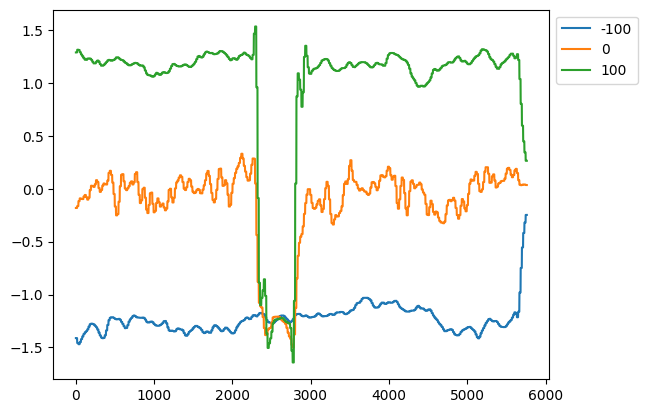

In [ ]:

# np.savez("Motion_Energy_all_pulse_fixed.npz", Motion_Energy=ME_T_ms, Motion_Energy_frames=ME_T, RDK_processed=RDK_processed, Coh=Coh, Pulse_Dur=pulse_dur, Pulse_time=pulse_t, Pulse_coh=pulse_coh)

import matplotlib.pyplot as plt

for i, coh in enumerate(Coh):
	plt.plot(ME_T_ms[i, :], label=str(coh))
plt.legend(bbox_to_anchor=(1, 1))
plt.show()